In [1]:
import pandas as pd
import numpy as np

PATH = "/kaggle/input/datasets/rmisra/news-category-dataset/News_Category_Dataset_v3.json"
df = pd.read_json(PATH, lines=True)

print(df.shape)
df.head()

(209527, 6)


,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


In [2]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/rmisra/news-category-dataset/News_Category_Dataset_v3.json


In [3]:
print(df.columns.tolist())
print(df.isna().sum())
print(df["category"].nunique(), "catégories")
df["category"].value_counts()

['link', 'headline', 'category', 'short_description', 'authors', 'date']
link                 0
headline             0
category             0
short_description    0
authors              0
date                 0
dtype: int64
42 catégories


category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3572
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2944
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2579
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2104
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1444
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ARTS & CULTURE     1339
COLLEGE            1144
LATINO VOICES      1130
CULTURE & ARTS     1074
EDUCATI

In [4]:
merge_map = {
    "ARTS": "ARTS & CULTURE", "CULTURE & ARTS": "ARTS & CULTURE",
    "TASTE": "FOOD & DRINK",
    "WORLDPOST": "WORLD NEWS", "THE WORLDPOST": "WORLD NEWS",
    "PARENTS": "PARENTING",
    "STYLE": "STYLE & BEAUTY",
    "HEALTHY LIVING": "WELLNESS",
    "MONEY": "BUSINESS",
    "SCIENCE": "SCIENCE & TECH", "TECH": "SCIENCE & TECH",
}
df["category"] = df["category"].replace(merge_map)

selected = [
    "POLITICS", "ENTERTAINMENT", "WELLNESS", "TRAVEL", "STYLE & BEAUTY",
    "PARENTING", "FOOD & DRINK", "BUSINESS", "SPORTS", "WORLD NEWS",
    "SCIENCE & TECH", "ARTS & CULTURE",
]
df = df[df["category"].isin(selected)].copy()

print(len(df), "articles")
print(df["category"].value_counts())

151352 articles
category
POLITICS          35602
WELLNESS          24639
ENTERTAINMENT     17362
PARENTING         12746
STYLE & BEAUTY    12068
TRAVEL             9900
WORLD NEWS         9542
FOOD & DRINK       8436
BUSINESS           7748
SPORTS             5077
SCIENCE & TECH     4310
ARTS & CULTURE     3922
Name: count, dtype: int64


In [5]:
df["text"] = (df["headline"].fillna("") + ". " + df["short_description"].fillna("")).str.strip()

df = df[df["text"].str.len() > 20]
df = df.drop_duplicates(subset="text")

df = df[["text", "category"]].reset_index(drop=True)
print(df.shape)
df.head()

(150823, 2)


,text,category
0,The Funniest Tweets From Parents This Week (Se...,PARENTING
1,Puerto Ricans Desperate For Water After Hurric...,WORLD NEWS
2,How A New Documentary Captures The Complexity ...,ARTS & CULTURE
3,Biden At UN To Call Russian War An Affront To ...,WORLD NEWS
4,World Cup Captains Want To Wear Rainbow Armban...,WORLD NEWS


In [6]:
assert len(df) >= 50000, "Moins de 50 000 articles"
assert df["category"].nunique() >= 5, "Moins de 5 catégories"
print("OK :", len(df), "articles,", df["category"].nunique(), "catégories")

OK : 150823 articles, 12 catégories


# Etape 2 : Prétraitement


In [7]:
import re      # expressions régulières pour le nettoyage
import spacy   # bibliothèque NLP utilisée pour la lemmatisation

# Chargement du modèle anglais (petit et rapide).
# On désactive "parser" et "ner" (analyse syntaxique et entités nommées)
# car on n'en a pas besoin : ça rend le traitement beaucoup plus rapide.
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

In [8]:
# --- Motifs de nettoyage (compilés une seule fois pour aller plus vite) ---
URL_RE = re.compile(r"http\S+|www\.\S+")   # détecte les liens (http..., www...)
HTML_RE = re.compile(r"<[^>]+>")           # détecte les balises HTML (<b>, <p>...)

def basic_clean(text):
    """Nettoyage de base avant spaCy : liens, balises HTML, espaces."""
    text = URL_RE.sub(" ", text)            # remplace les URLs par un espace
    text = HTML_RE.sub(" ", text)           # remplace les balises HTML par un espace
    return re.sub(r"\s+", " ", text).strip()  # réduit les espaces multiples et enlève ceux des bords

def doc_to_tokens(doc):
    """Transforme un texte analysé par spaCy en chaîne de lemmes propres."""
    return " ".join(
        t.lemma_.lower()          # lemme du mot, en minuscules (running -> run)
        for t in doc
        if t.is_alpha             # garde uniquement les mots (retire ponctuation et chiffres)
        and not t.is_stop         # retire les stopwords (the, is, and, of...)
        and len(t) > 2            # retire les mots de 1-2 lettres (peu informatifs)
    )

def preprocess_batch(texts, batch_size=1000):
    """Prétraite une liste de textes (rapide grâce à nlp.pipe)."""
    cleaned = [basic_clean(t) for t in texts]   # 1) nettoyage de base
    # 2) nlp.pipe traite les textes par lots : beaucoup plus rapide qu'un par un
    return [doc_to_tokens(d) for d in nlp.pipe(cleaned, batch_size=batch_size)]

def preprocess(text):
    """Prétraite UN seul texte (sera utilisée par le CLI à l'étape 6)."""
    return preprocess_batch([text])[0]

In [9]:
# 3 textes au hasard : on compare avant / après pour vérifier que ça marche
for t in df["text"].sample(3, random_state=1):
    print("AVANT :", t)
    print("APRÈS :", preprocess(t))
    print()

AVANT : Read The Full Text Of The Senate Health Care Bill. The bill has been largely a secret until now.
APRÈS : read text senate health care bill bill largely secret

AVANT : Ask Airfarewatchdog: Airline Vouchers, Frequent Flier Miles Never 'Free'. Whatever happened to "free" frequent flier tickets?
APRÈS : ask airfarewatchdog airline vouchers frequent flier miles free happen free frequent flier ticket

AVANT : Hillary Clinton Calls Senate Tax Bill 'Insulting Attack' On Americans. The bill was passed in Saturday's early morning hours.
APRÈS : hillary clinton call senate tax bill insulting attack americans bill pass saturday early morning hour



In [10]:
# Cellule 9 : prétraitement du corpus complet
df["clean_text"] = preprocess_batch(df["text"].tolist())
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
print(df.shape)

(150822, 3)


In [11]:
# Cellule 10 : vocabulaire avant/après + sauvegarde
vocab_avant = set(w for t in df["text"] for w in t.lower().split())
vocab_apres = set(w for t in df["clean_text"] for w in t.split())
print("Vocabulaire avant :", len(vocab_avant))
print("Vocabulaire après :", len(vocab_apres))
df.to_csv("/kaggle/working/corpus_clean.csv", index=False)

Vocabulaire avant : 213545
Vocabulaire après : 68175


# Représentation (TF-IDF vs Doc2Vec sur un échantillon)

In [12]:
# Cellule 11 : échantillon réduit + découpage train/test
from sklearn.model_selection import train_test_split

df_small = df.sample(n=20000, random_state=42)   # échantillon aléatoire de 20 000 articles

# Le découpage se fait AVANT d'ajuster TF-IDF/Doc2Vec (évite la fuite de données)
X_train, X_test, y_train, y_test = train_test_split(
    df_small["clean_text"], df_small["category"],
    test_size=0.2, random_state=42, stratify=df_small["category"]  # stratify : mêmes proportions de classes
)
print(len(X_train), "train /", len(X_test), "test")

16000 train / 4000 test


In [13]:
# Cellule 12 : TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# max_features : garde les 20 000 termes les plus utiles
# ngram_range=(1,2) : mots seuls + paires de mots ("health care")
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
Xtr_tfidf = tfidf.fit_transform(X_train)   # fit sur le train uniquement
Xte_tfidf = tfidf.transform(X_test)
print("TF-IDF :", Xtr_tfidf.shape)

TF-IDF : (16000, 20000)


In [14]:
# Cellule 13 : Doc2Vec
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
import numpy as np

# Chaque document = liste de mots + un identifiant
train_docs = [TaggedDocument(words=t.split(), tags=[i]) for i, t in enumerate(X_train)]

# vector_size=100 : chaque article devient un vecteur dense de 100 nombres
d2v = Doc2Vec(vector_size=100, min_count=2, epochs=20, workers=4, seed=42)
d2v.build_vocab(train_docs)
d2v.train(train_docs, total_examples=d2v.corpus_count, epochs=d2v.epochs)

Xtr_d2v = np.array([d2v.dv[i] for i in range(len(X_train))])               # vecteurs appris
Xte_d2v = np.array([d2v.infer_vector(t.split()) for t in X_test])          # vecteurs inférés pour le test
print("Doc2Vec :", Xtr_d2v.shape)

Doc2Vec : (16000, 100)


In [15]:
# Cellule 14 : comparaison des deux représentations (livrable étape 3)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

resultats = []
for nom, (Xtr, Xte) in {"TF-IDF": (Xtr_tfidf, Xte_tfidf),
                        "Doc2Vec": (Xtr_d2v, Xte_d2v)}.items():
    clf = LogisticRegression(max_iter=1000, class_weight="balanced")
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xte)
    resultats.append((nom, accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")))

pd.DataFrame(resultats, columns=["Représentation", "Accuracy", "F1 macro"])

,Représentation,Accuracy,F1 macro
0,TF-IDF,0.73325,0.684719
1,Doc2Vec,0.48475,0.440237


# Étape 4 : Modélisation (corpus complet, TF-IDF)

In [16]:
# Cellule 15 : découpage sur le corpus complet
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["category"],
    test_size=0.2, random_state=42, stratify=df["category"]
)

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print(Xtr.shape, Xte.shape)

(120657, 20000) (30165, 20000)


In [17]:
# Cellule 16 : régression logistique
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1)
logreg.fit(Xtr, y_train)
pred_lr = logreg.predict(Xte)

In [18]:
# Cellule 17 : Random Forest (peut prendre plusieurs minutes)
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(Xtr, y_train)
pred_rf = rf.predict(Xte)

# Étape 5 : Évaluation

In [19]:
# Cellule 18 : métriques comparées
from sklearn.metrics import classification_report

for nom, pred in [("Régression logistique", pred_lr), ("Random Forest", pred_rf)]:
    print("=====", nom, "=====")
    print("Accuracy :", round(accuracy_score(y_test, pred), 4))
    print("F1 macro :", round(f1_score(y_test, pred, average="macro"), 4))
    print(classification_report(y_test, pred))

===== Régression logistique =====
Accuracy : 0.7764
F1 macro : 0.7389
                precision    recall  f1-score   support

ARTS & CULTURE       0.49      0.67      0.57       782
      BUSINESS       0.57      0.69      0.62      1546
 ENTERTAINMENT       0.81      0.76      0.78      3468
  FOOD & DRINK       0.76      0.85      0.80      1685
     PARENTING       0.77      0.78      0.77      2532
      POLITICS       0.92      0.79      0.85      7107
SCIENCE & TECH       0.47      0.66      0.55       852
        SPORTS       0.69      0.84      0.76      1014
STYLE & BEAUTY       0.85      0.83      0.84      2385
        TRAVEL       0.78      0.79      0.78      1976
      WELLNESS       0.83      0.75      0.79      4913
    WORLD NEWS       0.69      0.80      0.74      1905

      accuracy                           0.78     30165
     macro avg       0.72      0.77      0.74     30165
  weighted avg       0.79      0.78      0.78     30165

===== Random Forest =====
Accur

In [20]:
# Cellule 18b : mAP (mean Average Precision, one-vs-rest)
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import label_binarize

classes = logreg.classes_
y_bin = label_binarize(y_test, classes=classes)

for nom, model in [("Régression logistique", logreg), ("Random Forest", rf)]:
    ap = average_precision_score(y_bin, model.predict_proba(Xte), average=None)
    print("=====", nom, "=====")
    print(pd.Series(ap, index=classes).round(3).to_string())
    print("mAP :", round(ap.mean(), 4))

===== Régression logistique =====
ARTS & CULTURE    0.585
BUSINESS          0.641
ENTERTAINMENT     0.848
FOOD & DRINK      0.843
PARENTING         0.813
POLITICS          0.932
SCIENCE & TECH    0.613
SPORTS            0.795
STYLE & BEAUTY    0.909
TRAVEL            0.848
WELLNESS          0.864
WORLD NEWS        0.786
mAP : 0.7898
===== Random Forest =====
ARTS & CULTURE    0.483
BUSINESS          0.514
ENTERTAINMENT     0.753
FOOD & DRINK      0.787
PARENTING         0.741
POLITICS          0.892
SCIENCE & TECH    0.492
SPORTS            0.703
STYLE & BEAUTY    0.838
TRAVEL            0.730
WELLNESS          0.785
WORLD NEWS        0.683
mAP : 0.7


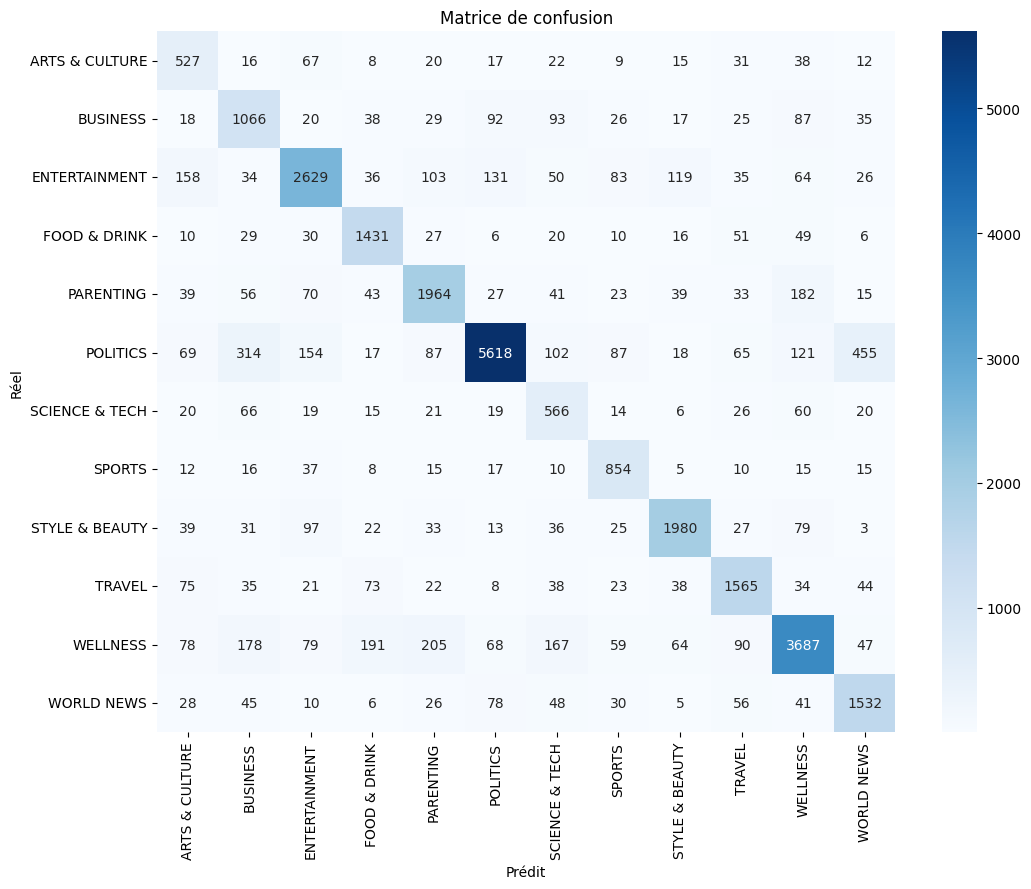

In [21]:
# Cellule 19 : matrice de confusion du meilleur modèle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

best_pred = pred_lr   # remplace par pred_rf si le RF est meilleur
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, best_pred, labels=labels)

plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion.png", dpi=150)
plt.show()

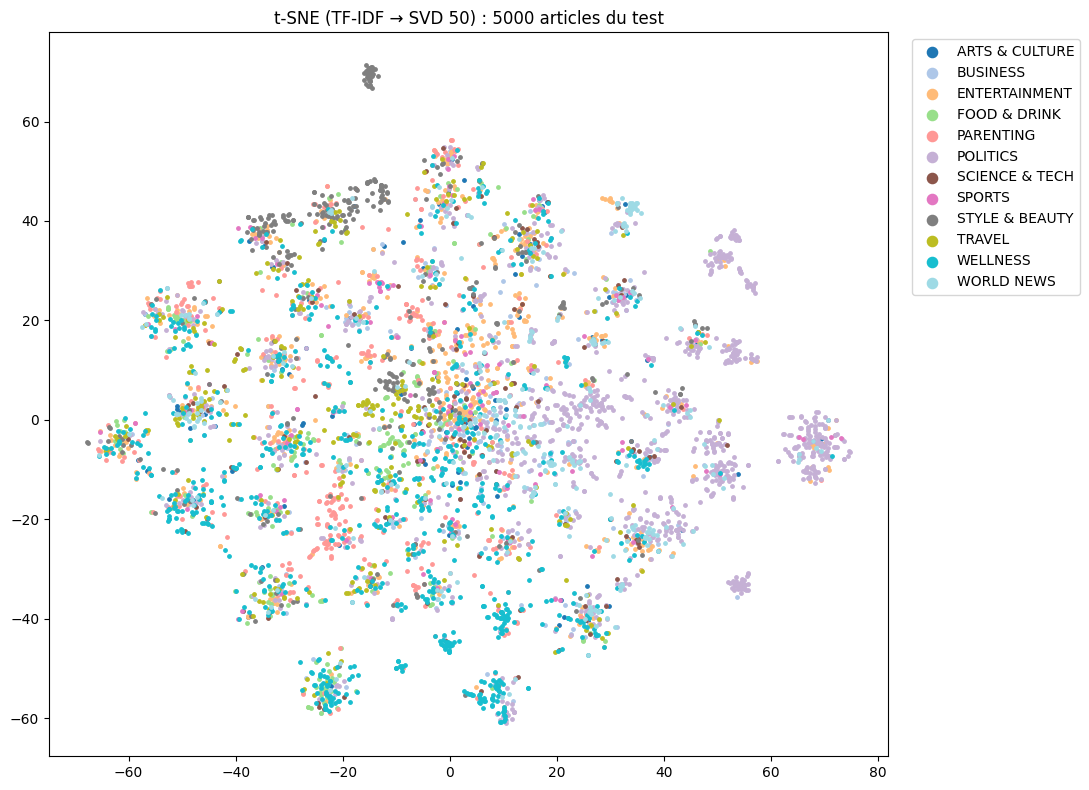

In [22]:
# Cellule 19b : visualisation t-SNE de l'espace des thèmes
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

idx = np.random.RandomState(42).choice(Xte.shape[0], 5000, replace=False)
X_red = TruncatedSVD(n_components=50, random_state=42).fit_transform(Xte[idx])   # accélère t-SNE
X_2d = TSNE(n_components=2, init="pca", perplexity=30, random_state=42).fit_transform(X_red)

y_s = y_test.iloc[idx].values
colors = plt.cm.tab20(np.linspace(0, 1, 12))
plt.figure(figsize=(11, 8))
for i, c in enumerate(sorted(set(y_s))):
    m = y_s == c
    plt.scatter(X_2d[m, 0], X_2d[m, 1], s=6, color=colors[i], label=c)
plt.legend(markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("t-SNE (TF-IDF → SVD 50) : 5000 articles du test")
plt.tight_layout()
plt.savefig("/kaggle/working/tsne.png", dpi=150)
plt.show()

# Export 

In [23]:
# Cellule 20 : sauvegarde des modèles (choisis le meilleur comme modèle final)
import joblib, sklearn, spacy
joblib.dump(tfidf,  "/kaggle/working/tfidf.joblib")
joblib.dump(logreg, "/kaggle/working/logreg.joblib")
joblib.dump(rf,     "/kaggle/working/rf.joblib")   # attention : fichier volumineux

print("scikit-learn", sklearn.__version__)
print("spacy", spacy.__version__)

scikit-learn 1.6.1
spacy 3.8.16


In [24]:
# New cell after cell 15
test_df = df.loc[X_test.index, ["text", "category"]]
test_df.to_csv("/kaggle/working/test_set.csv", index=False)
print(test_df.shape)   # about (30165, 2)

(30165, 2)


In [25]:
test_df = df.loc[X_test.index, ["text", "category"]]
pd.set_option("display.max_colwidth", 200)
test_df.sample(10, random_state=3)

,text,category
35218,Chrissy Teigen Got Creative When John Legend Couldn’t Be In Santa Pic. This is a gift.,ENTERTAINMENT
104300,"Behind The Scenes Of 'Maury'. Listen to the familiar voice of Maury Povich: ""This is Tiffany. In two months, Tiffany is marrying her fiancé, Cornelius",ENTERTAINMENT
70820,"American Pharoah Wins Preakness Stakes, Setting Up Triple Crown Shot.",SPORTS
110122,Eric Ripert's Dream Kitchen. Le Bernardin's master chef on kitchen-design lessons home cooks can take from a professional one.,FOOD & DRINK
62333,"Steve Jobs' Widow Begged DiCaprio, Bale Not To Play Her Husband. Michael Fassbender ended up getting the part.",ENTERTAINMENT
47078,"Can Growing Human Organs in Pigs Solve the Organ Shortage?. Back in the 90s, a deeply disturbing image surfaced on the nascent Internet: a lab mouse with something looking like a human",WORLD NEWS
72907,"As Important as the Intended Artwork Is Selecting the Right Print Studio or Foundry. Art is often a solitary pursuit but, sometimes, even the most reclusive artists must seek out the help and serv...",ARTS & CULTURE
51912,Pinkies Up! There Could Be Some Real Health Benefits To Drinking Tea. Just don't add the milk.,WELLNESS
49264,"Arianna Applauds Lindsey Graham For Rejecting Donald Trump. ""Good for Lindsey Graham.""",POLITICS
80030,"An Interview With Food Revolutionary Michael Pollan. Michael Pollan is a food activist, journalist, and bestselling author whose books have revolutionized the way Americans think about food. What ...",FOOD & DRINK


In [26]:
test_df.groupby("category").head(1)

,text,category
37966,This May Be The Most Sweeping Set Of Animal Protections Ever Announced. Tens of millions of animals will be spared from suffering. 🐔,BUSINESS
17066,Weekend Roundup: The Battle For Europe. Wary German voters and Catalan separatists are foiling the French vision of shared sovereignty.,WORLD NEWS
82722,It's Safe To Say That Emma Roberts Has Never Looked So Good.,STYLE & BEAUTY
84231,Videocracy - Filmed Violence That Galvanizes Opinion and Policy (See ISIS and Women). Katrina and Lowry debate whether a) beheadings and media war whoops forced Obama's hand; b) he gets a boost or...,POLITICS
91097,"6 Simple Ways to Parent More Effectively. We don't need to model getting everything right. That would be too neurotic. It's OK to mess up. We just need to model taking responsibility, apologizing ...",PARENTING
100531,"New Year, New Jobs. Thanks to several key trends in aging and health care, one of the fastest-growing jobs in 2014 is expected to be that of",WELLNESS
106679,"Climbing Major Mountains - For the Rest of Us. To get an idea of what it takes to prepare for a climb up Everest or for any other advanced trek, here is a sample of the things that some guide serv...",TRAVEL
109458,"Why Poetry Makes Sense: An Interview With Stephen Burt. Stephen Burt and I discussed the instructive and useful nature of poetry: how it's a vehicle for self-expression, a valuable means of unders...",ARTS & CULTURE
61270,"Why This Young Couple Is Terrified Their Baby Will Be Taken From Them. Karen says she wants custody of her 20-year-old daughter, Kiersten’s, unborn baby girl, because she believes Kiersten and",ENTERTAINMENT
131677,"The Grossest, Goriest Halloween Recipes Ever (PHOTOS). The sight might turn your stomach, but we promise the taste won't.",FOOD & DRINK
